# 01 - EDA AND CLEANING

Phone price dataset: load, inspect, clean, explore and visualize.  
Output: `data/processed/mobile_phone_price_clean.csv`.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import random
import math
import os
import re

os.makedirs("../reports/figures", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

print("libraries imported successfully")

libraries imported successfully


# LOAD THE DATA INTO A PANDAS DATAFRAME

In [3]:
df = pd.read_csv("../data/raw/mobile_phone_price.csv")

df

,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($)
0,Apple,iPhone 13 Pro,128 GB,6 GB,6.1,12 + 12 + 12,3095,999
1,Samsung,Galaxy S21 Ultra,256 GB,12 GB,6.8,108 + 10 + 10 + 12,5000,1199
2,OnePlus,9 Pro,128 GB,8 GB,6.7,48 + 50 + 8 + 2,4500,899
3,Xiaomi,Redmi Note 10 Pro,128 GB,6 GB,6.67,64 + 8 + 5 + 2,5020,279
4,Google,Pixel 6,128 GB,8 GB,6.4,50 + 12.2,4614,799
...,...,...,...,...,...,...,...,...
402,Samsung,Galaxy Note20 5G,128,8,6.7,12+64+12,4300,1049
403,Xiaomi,Mi 10 Lite 5G,128,6,6.57,48+8+2+2,4160,349
404,Apple,iPhone 12 Pro Max,128,6,6.7,12+12+12,3687,1099
405,Oppo,Reno3,128,8,6.4,48+13+8+2,4025,429


# INSPECT THE DATA

In [4]:
print("\nshape of the dataset",df.shape)
print('\nFeature Names')
print(df.columns.tolist())
print('\nBasic Information')
print(df.info())


shape of the dataset (407, 8)

Feature Names
['Brand', 'Model', 'Storage ', 'RAM ', 'Screen Size (inches)', 'Camera (MP)', 'Battery Capacity (mAh)', 'Price ($)']

Basic Information
<class 'pandas.DataFrame'>
RangeIndex: 407 entries, 0 to 406
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Brand                   407 non-null    str  
 1   Model                   407 non-null    str  
 2   Storage                 407 non-null    str  
 3   RAM                     407 non-null    str  
 4   Screen Size (inches)    407 non-null    str  
 5   Camera (MP)             407 non-null    str  
 6   Battery Capacity (mAh)  407 non-null    int64
 7   Price ($)               407 non-null    str  
dtypes: int64(1), str(7)
memory usage: 25.6 KB
None


# Data Formatting

In [5]:
df.columns = df.columns.str.strip()
df['Storage'] = df['Storage'].str.extract(r'(\d+)')[0].astype(int)
df['RAM'] = df['RAM'].str.extract(r'(\d+)')[0].astype(int)
df['Price ($)'] = df['Price ($)'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(int)
df['Screen Size (inches)'] = df['Screen Size (inches)'].str.extract(r'(\d+\.?\d*)')[0].astype(float)

# CAMERA FEATURE ENGINEERING

The raw `Camera (MP)` column is a string such as `48MP + 8MP + 2MP + 2MP`, with inconsistent formatting (`MP` suffix or not).
Summing the lenses is not meaningful: megapixels from different lenses do not add up, and a phone with three 2 MP lenses would score higher than a phone with one excellent lens.
The dataset does **not** label the lens types, so the lens names below are **inferred** from order and resolution.

### Basic assumptions

1. **Order:** the lenses are listed in order of importance, so the **first lens is the main camera**.
2. **Low-resolution lenses:** any lens of **5 MP or less** is a *macro* lens. Macro and depth sensors are both low resolution (usually 2 to 5 MP) and cannot be told apart from the data, so they are grouped as *macro*.
3. **Ultra-wide vs telephoto:** among the remaining lenses (above 5 MP), the **first is the ultra-wide** and the **second is the telephoto**.
4. **One value per lens type:** if a phone has several lenses of the same type (e.g. two 2 MP lenses), only the first one is stored. The total number of lenses is kept in `Num_camera`.
5. **Absent lens = 0 MP.** `Num_camera` tells the model how many lenses really exist.
6. **Depth/ToF tokens** such as `3D` or `ToF` are not megapixel lenses and are ignored.


### Lens types (short note)

- **Main (wide):** the primary camera, highest resolution, used for most photos.
- **Ultra-wide:** wider field of view, fits more of the scene into the frame.
- **Telephoto:** optical zoom, for distant subjects.
- **Macro:** extreme close-ups of tiny objects, low resolution (2 to 5 MP). Depth sensors are also 2 to 5 MP, so they are grouped here.

In [ ]:
def parse_lenses(val):
    # Return the MP of each lens in order of appearance. Non-MP tokens (3D, ToF) are skipped.
    lenses = []
    for part in str(val).split('+'):
        m = re.fullmatch(r'\s*(\d+\.?\d*)\s*(?:MP)?\s*', part, flags=re.I)
        if m:
            lenses.append(float(m.group(1)))
    return lenses


MACRO_MAX_MP = 5   # assumption 2


def name_lenses(lenses):
    # Assign lens names from order and resolution (see assumptions above).
    main = lenses[0]                                   # assumption 1
    rest = lenses[1:]
    macro = [x for x in rest if x <= MACRO_MAX_MP]     # assumption 2
    wide_or_tele = [x for x in rest if x > MACRO_MAX_MP]
    return pd.Series({
        'Num_camera':    len(lenses),
        'Cam_main':      main,
        'Cam_ultra':     wide_or_tele[0] if len(wide_or_tele) > 0 else 0.0,   # assumption 3
        'Cam_telephoto': wide_or_tele[1] if len(wide_or_tele) > 1 else 0.0,   # assumption 3
        'Cam_macro':     macro[0] if macro else 0.0,                          # assumption 4
        'ambiguous':     len(wide_or_tele) >= 2,   # ultra vs telephoto order cannot be verified
    })


lens_list = df['Camera (MP)'].apply(parse_lenses)
assert (lens_list.apply(len) >= 1).all(), "Some rows have no parsable camera"

df = pd.concat([df, lens_list.apply(name_lenses)], axis=1)

n_amb = int(df['ambiguous'].sum())
print(f"Rows where ultra vs telephoto is ambiguous (2+ lenses above {MACRO_MAX_MP} MP): {n_amb} of {len(df)} ({n_amb/len(df):.1%})")

display(df[['Brand', 'Model', 'Camera (MP)', 'Num_camera', 'Cam_main', 'Cam_ultra', 'Cam_telephoto', 'Cam_macro']].sample(10, random_state=42))

Rows where ultra vs telephoto is ambiguous (2+ lenses above 5 MP): 60 of 407 (14.7%)


,Brand,Model,Camera (MP),Num_camera,Cam_main,Cam_ultra,Cam_telephoto,Cam_macro
70,Realme,C25s,13 + 2 + 2,3,13.0,0.0,0.0,2.0
218,Xiaomi,Redmi 9i,13MP,1,13.0,0.0,0.0,0.0
258,Samsung,Galaxy M31s,64MP + 12MP + 5MP + 5MP,4,64.0,12.0,0.0,5.0
33,Oppo,A53s,13 + 2 + 2,3,13.0,0.0,0.0,2.0
42,Samsung,Galaxy F22,48 + 8 + 2 + 2,4,48.0,8.0,0.0,2.0
77,Apple,iPhone 13,12MP + 12MP,2,12.0,12.0,0.0,0.0
137,Xiaomi,Poco M3 Pro 5G,48MP + 2MP + 2MP,3,48.0,0.0,0.0,2.0
334,Samsung,Galaxy M51,64+12+5+5,4,64.0,12.0,0.0,5.0
245,Nokia,G20,48MP + 5MP + 2MP + 2MP,4,48.0,0.0,0.0,5.0
266,Vivo,Y51A,48MP + 8MP + 2MP,3,48.0,8.0,0.0,2.0


In [7]:
# sanity check done, drop the raw string and the helper flag
df = df.drop(columns=['Camera (MP)', 'ambiguous'])
df['Num_camera'] = df['Num_camera'].astype(int)

# DESCRIBE THE DATA

In [8]:
display(df.describe().round(2))
print('\nNumber of Unique Brands: ',df['Brand'].nunique())
print('Number of Unique Models: ',df['Model'].nunique())

,Storage,RAM,Screen Size (inches),Battery Capacity (mAh),Price ($),Num_camera,Cam_main,Cam_ultra,Cam_telephoto,Cam_macro
count,407.00,407.00,407.00,407.00,407.00,407.00,407.00,407.0,407.00,407.00
mean,123.05,5.84,6.47,4676.48,408.31,3.13,43.32,8.2,1.86,2.33
std,64.96,2.43,0.32,797.19,299.68,0.78,24.67,10.8,5.28,1.71
min,32.00,2.00,4.50,1821.00,99.00,1.00,8.00,0.0,0.00,0.00
25%,64.00,4.00,6.44,4300.00,199.00,3.00,13.00,0.0,0.00,2.00
50%,128.00,6.00,6.50,5000.00,299.00,3.00,48.00,8.0,0.00,2.00
75%,128.00,8.00,6.59,5000.00,499.00,4.00,64.00,12.0,0.00,2.00
max,512.00,16.00,7.60,7000.00,1999.00,4.00,108.00,64.0,48.00,5.00



Number of Unique Brands:  16
Number of Unique Models:  239


# CHECK FOR MISSING DATA

In [9]:
print("\nMissing values:")
display(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())


Missing values:


Brand                     0
Model                     0
Storage                   0
RAM                       0
Screen Size (inches)      0
Battery Capacity (mAh)    0
Price ($)                 0
Num_camera                0
Cam_main                  0
Cam_ultra                 0
Cam_telephoto             0
Cam_macro                 0
dtype: int64


Total missing values:
0


# CHECK FOR DUPLICATE DATA

In [10]:
duplicates=df.duplicated().sum()
print('Number of duplicate rows: ',duplicates)

if duplicates>0:
    df=df.drop_duplicates()
    print('\nDuplicates removed')
else:
    print('No duplicates')

Number of duplicate rows:  49

Duplicates removed


# BASIC DATA CLEANING

In [11]:
df = df.rename(columns={
    "Screen Size (inches)": "Screen_size",
    "Battery Capacity (mAh)": "Battery_cap",
    "Price ($)": "Price",
})

df = df[["Brand", "Model", "Storage", "RAM", "Screen_size",
         "Num_camera", "Cam_main", "Cam_ultra", "Cam_telephoto", "Cam_macro",
         "Battery_cap", "Price"]]

print("Cleaned column names:")
print(df.columns.tolist())

Cleaned column names:
['Brand', 'Model', 'Storage', 'RAM', 'Screen_size', 'Num_camera', 'Cam_main', 'Cam_ultra', 'Cam_telephoto', 'Cam_macro', 'Battery_cap', 'Price']


# EXPLORE THE DATA

In [12]:
print("Number of observations per Brand:")
display(df["Brand"].value_counts())

print("\nAverage measurements by Brand:")
display(
    df.groupby("Brand")[
        ["Storage",
         "RAM",
         "Screen_size",
         "Num_camera",
         "Cam_main",
         "Cam_ultra",
         "Cam_telephoto",
         "Cam_macro",
         "Battery_cap",
         "Price"]
    ].mean().round(2)
)

Number of observations per Brand:


Brand
Samsung       64
Xiaomi        57
Oppo          51
Realme        42
Vivo          31
Apple         25
Nokia         24
Motorola      22
OnePlus       13
Huawei        12
Google         5
Asus           4
LG             3
Blackberry     3
Sony           1
CAT            1
Name: count, dtype: int64


Average measurements by Brand:


,Storage,RAM,Screen_size,Num_camera,Cam_main,Cam_ultra,Cam_telephoto,Cam_macro,Battery_cap,Price
Brand,,,,,,,,,,
Apple,138.24,4.08,5.96,2.20,12.00,9.88,4.32,0.00,2971.64,783.00
Asus,160.00,7.50,6.50,2.75,64.00,12.25,5.00,1.25,5000.00,874.00
Blackberry,64.00,5.33,5.00,2.00,12.33,8.33,0.00,1.67,3500.00,499.00
CAT,32.00,3.00,5.50,2.00,13.00,0.00,0.00,5.00,4200.00,299.00
Google,128.00,7.20,6.14,2.00,27.32,14.44,0.00,0.00,3995.80,699.00
Huawei,218.67,7.33,6.52,3.33,48.83,16.00,11.33,1.00,4161.67,783.17
LG,170.67,6.67,6.77,3.33,58.67,7.00,4.00,3.33,4100.00,615.67
Motorola,104.73,4.50,6.58,3.05,55.86,5.45,1.09,2.32,5022.73,272.64
Nokia,72.00,3.79,6.52,2.83,29.67,1.71,0.00,3.67,4500.00,230.25


# VISUALIZE THE DATA

In [13]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

BLUE, RED, GREEN, GREY = "#4C72B0", "#C44E52", "#55A868", "#B0B0B0"
usd = mtick.StrMethodFormatter("${x:,.0f}")

### Target variable

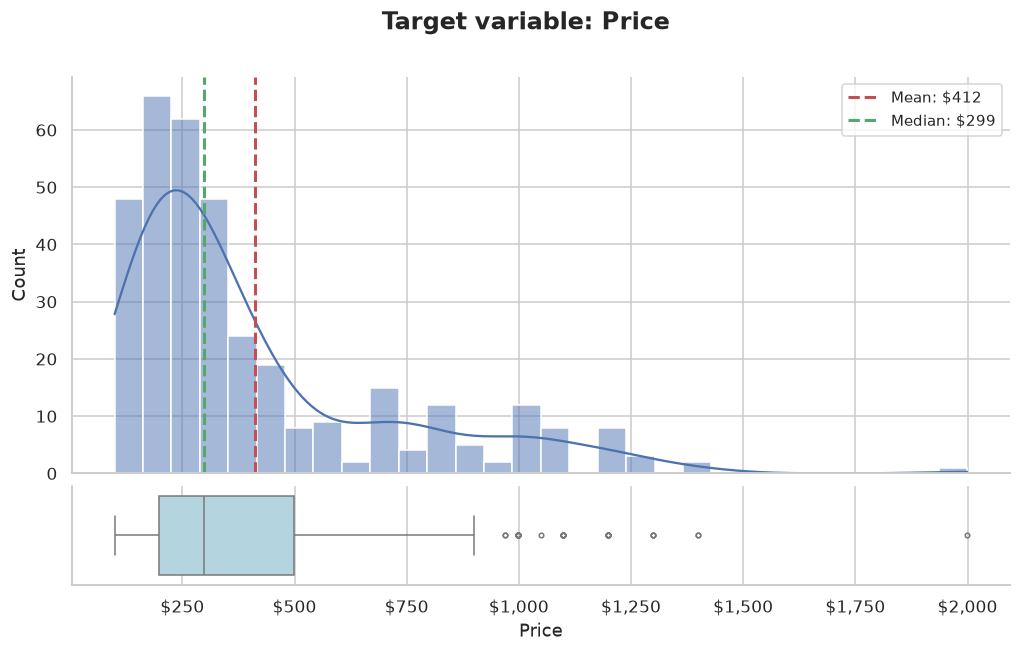

In [14]:
price_mean, price_median = df['Price'].mean(), df['Price'].median()

fig, (ax_hist, ax_box) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True,
    gridspec_kw={"height_ratios": [4, 1], "hspace": 0.05}
)
fig.suptitle('Target variable: Price', fontsize=16, fontweight='bold')

# Histogram + KDE
sns.histplot(df['Price'], bins=30, kde=True, color=BLUE, edgecolor='white', ax=ax_hist)
ax_hist.axvline(price_mean, color=RED, ls='--', lw=2, label=f'Mean: ${price_mean:,.0f}')
ax_hist.axvline(price_median, color=GREEN, ls='--', lw=2, label=f'Median: ${price_median:,.0f}')
ax_hist.set_ylabel('Count')
ax_hist.set_xlabel('')
ax_hist.legend(fontsize=10)

# Box plot (same x axis as the histogram)
sns.boxplot(x=df['Price'], color='lightblue', ax=ax_box, fliersize=3)
ax_box.set_xlabel('Price')
ax_box.set_yticks([])
ax_box.xaxis.set_major_formatter(usd)

plt.savefig("../reports/figures/target_variable_price.png", bbox_inches="tight", dpi=110)
plt.show()

### Specs vs Price

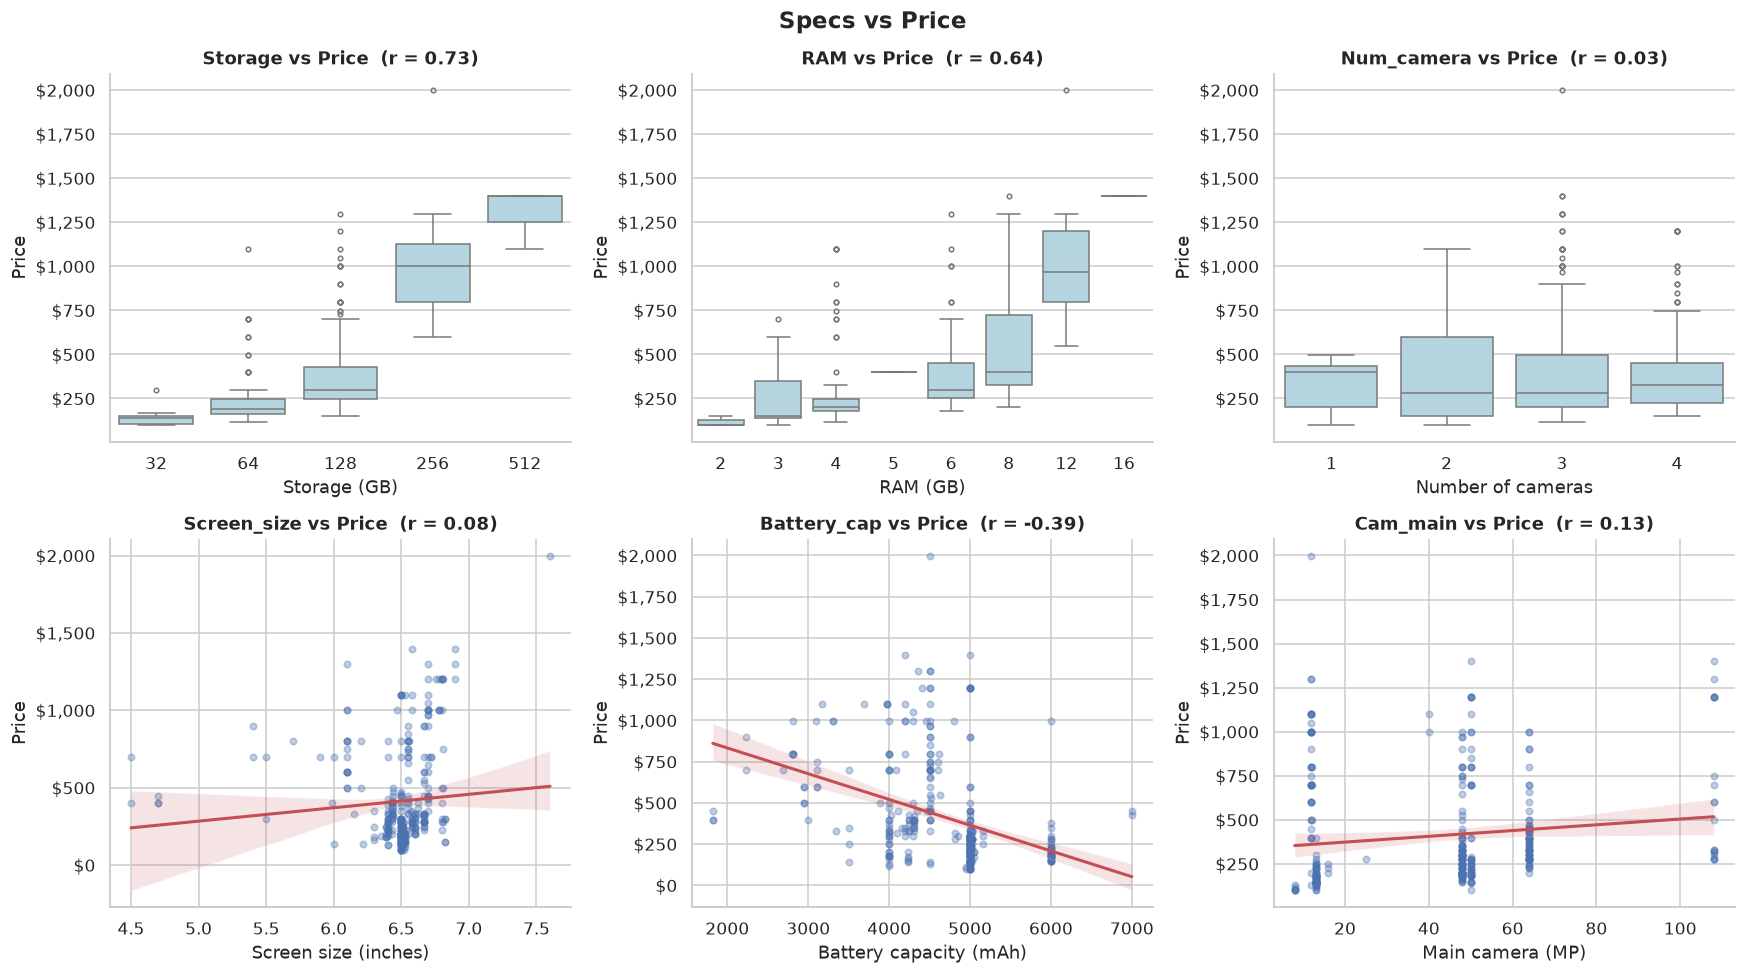

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Specs vs Price', fontsize=15, fontweight='bold')

# discrete features -> box plot per value
for ax, feat, label in zip(axes[0], ['Storage', 'RAM', 'Num_camera'],
                           ['Storage (GB)', 'RAM (GB)', 'Number of cameras']):
    order = sorted(df[feat].unique())
    sns.boxplot(data=df, x=feat, y='Price', order=order, color='lightblue', fliersize=3, ax=ax)
    ax.set_xlabel(label)
    ax.set_ylabel('Price')
    ax.yaxis.set_major_formatter(usd)
    ax.set_title(f'{feat} vs Price  (r = {df[feat].corr(df["Price"]):.2f})')

# continuous features -> scatter + trend line
for ax, feat, label in zip(axes[1], ['Screen_size', 'Battery_cap', 'Cam_main'],
                           ['Screen size (inches)', 'Battery capacity (mAh)', 'Main camera (MP)']):
    sns.regplot(data=df, x=feat, y='Price', ax=ax,
                scatter_kws={'alpha': 0.35, 's': 18, 'color': BLUE},
                line_kws={'color': RED, 'lw': 2})
    ax.set_xlabel(label)
    ax.set_ylabel('Price')
    ax.yaxis.set_major_formatter(usd)
    ax.set_title(f'{feat} vs Price  (r = {df[feat].corr(df["Price"]):.2f})')

plt.tight_layout()
plt.savefig("../reports/figures/specs_vs_price.png", bbox_inches="tight", dpi=110)
plt.show()

### Secondary lenses vs Price (present / absent)

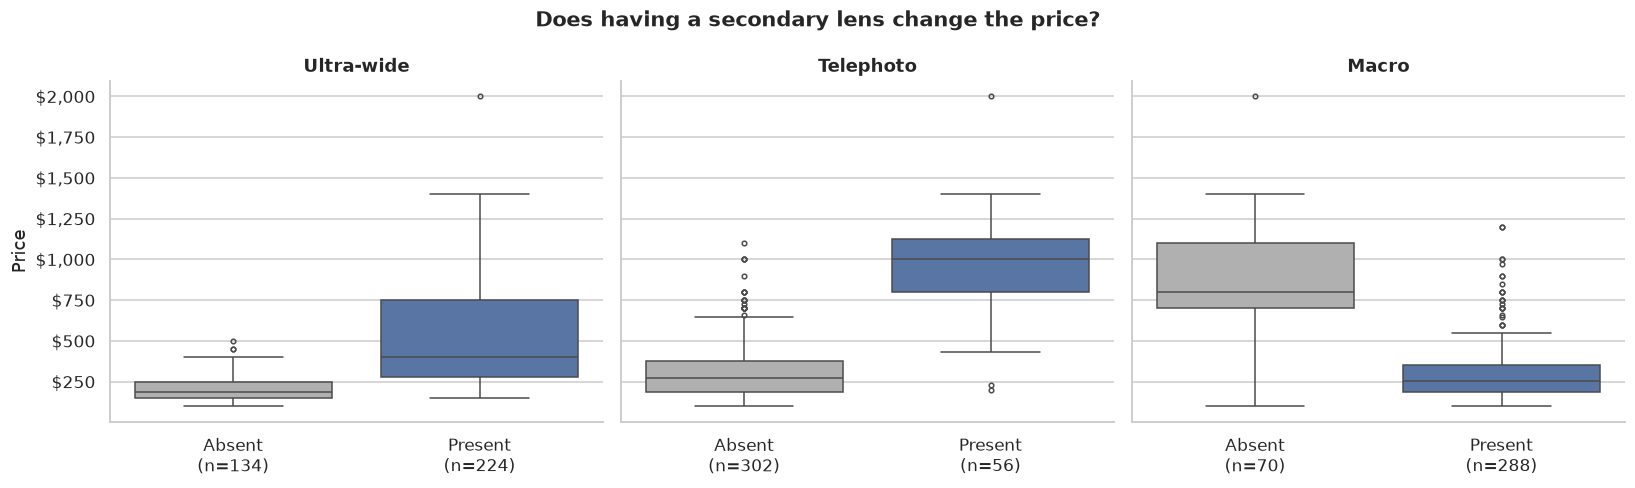

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
fig.suptitle('Does having a secondary lens change the price?', fontsize=14, fontweight='bold')

for ax, feat, title in zip(axes, ['Cam_ultra', 'Cam_telephoto', 'Cam_macro'],
                           ['Ultra-wide', 'Telephoto', 'Macro']):
    has_lens = np.where(df[feat] > 0, 'Present', 'Absent')
    n_abs, n_pre = (has_lens == 'Absent').sum(), (has_lens == 'Present').sum()
    sns.boxplot(x=has_lens, y=df['Price'], order=['Absent', 'Present'],
                hue=has_lens, hue_order=['Absent', 'Present'],
                palette={'Absent': GREY, 'Present': BLUE},
                legend=False, fliersize=3, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels([f'Absent\n(n={n_abs})', f'Present\n(n={n_pre})'])
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('Price')
    ax.yaxis.set_major_formatter(usd)

plt.tight_layout()
plt.savefig("../reports/figures/lenses_vs_price.png", bbox_inches="tight", dpi=110)
plt.show()

### Average price by brand

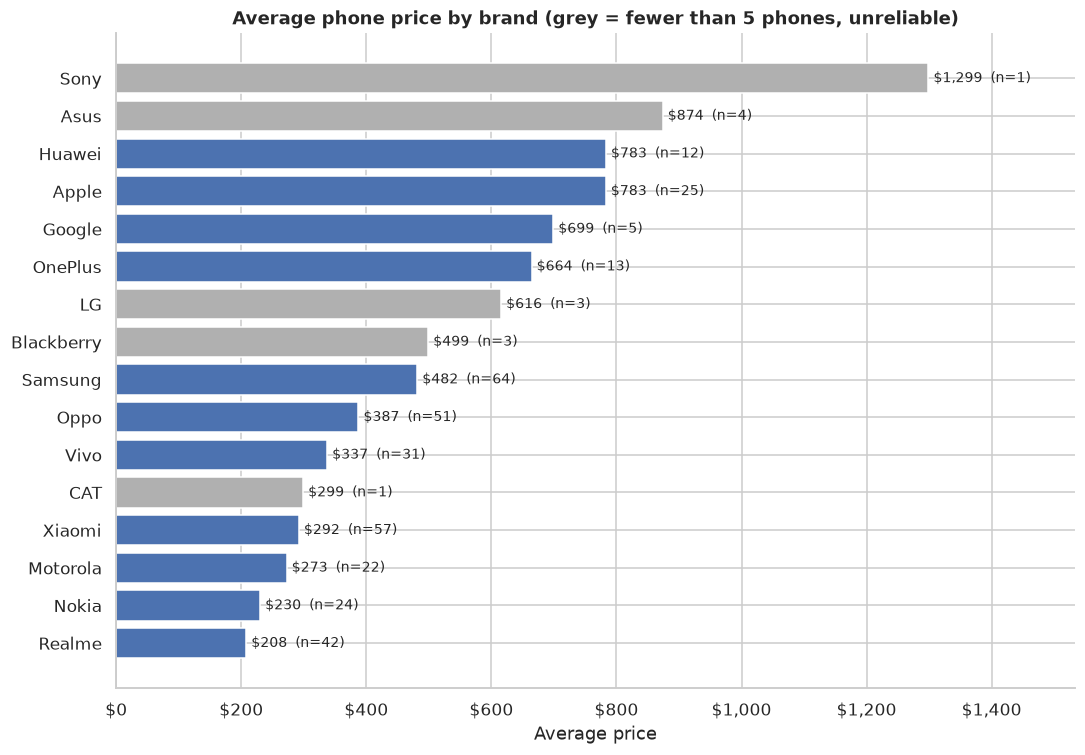

In [17]:
brand_stats = (df.groupby('Brand')['Price']
                 .agg(['mean', 'count'])
                 .sort_values('mean', ascending=True))

MIN_N = 5
colors = [BLUE if n >= MIN_N else GREY for n in brand_stats['count']]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(brand_stats.index, brand_stats['mean'], color=colors)

for bar, (mean_price, n) in zip(bars, zip(brand_stats['mean'], brand_stats['count'])):
    ax.text(bar.get_width() + 8, bar.get_y() + bar.get_height() / 2,
            f'${mean_price:,.0f}  (n={n})', va='center', fontsize=9)

ax.set_title(f'Average phone price by brand (grey = fewer than {MIN_N} phones, unreliable)')
ax.set_xlabel('Average price')
ax.xaxis.set_major_formatter(usd)
ax.set_xlim(0, brand_stats['mean'].max() * 1.18)

plt.tight_layout()
plt.savefig("../reports/figures/brand_avg_price.png", bbox_inches="tight", dpi=110)
plt.show()

# CORRELATION ANALYSIS

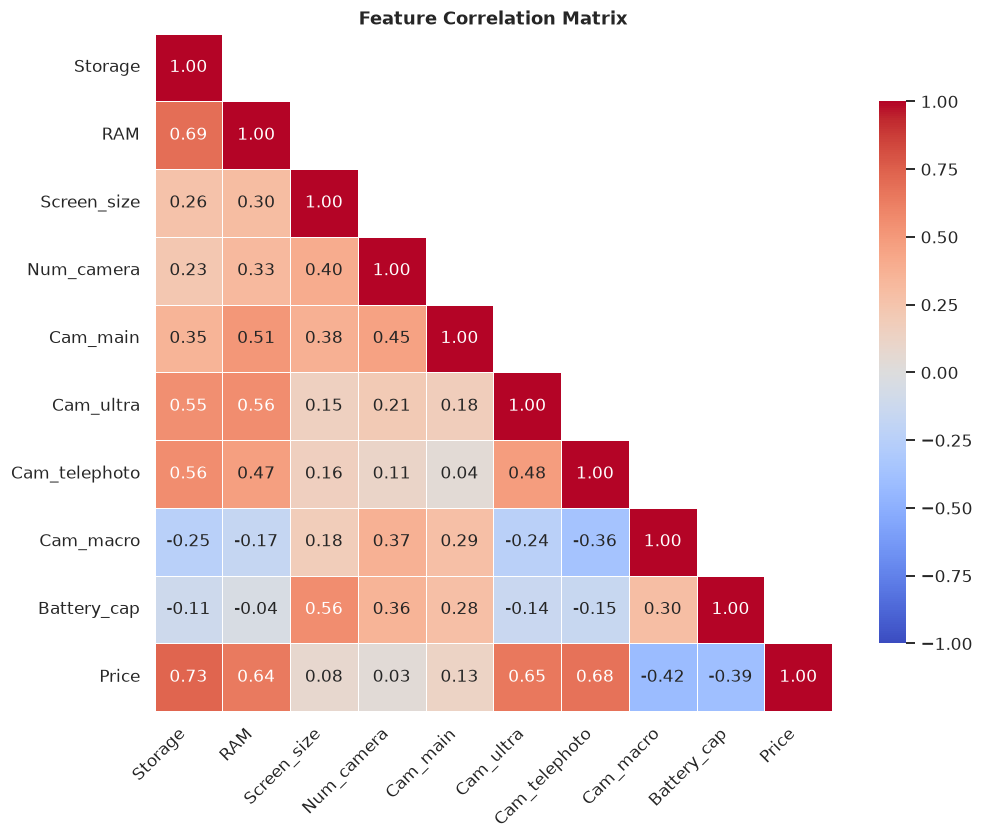

In [18]:
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # hide the duplicated upper triangle

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, linewidths=0.5, square=True,
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title("Feature Correlation Matrix")
ax.grid(False)
plt.xticks(rotation=45, ha='right')
plt.savefig("../reports/figures/correlation_matrix.png", bbox_inches="tight", dpi=110)
plt.show()

# SAVE THE CLEANED DATA

In [19]:
df.to_csv("../data/processed/mobile_phone_price_clean.csv", index=False)
print("Saved cleaned data:", df.shape)

Saved cleaned data: (358, 12)
